In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
df = pd.read_csv("UrbanCabFare.csv")
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   User_ID               1000 non-null   object 
 1   Driver_Name           985 non-null    object 
 2   City                  1000 non-null   object 
 3   Ride_Date             1000 non-null   object 
 4   Hour_of_Day           1000 non-null   int64  
 5   Day_of_Week           1000 non-null   object 
 6   Distance_km           1000 non-null   float64
 7   Traffic_Level         1000 non-null   object 
 8   Type_of_vehicle       1000 non-null   object 
 9   No_of_active_drivers  1000 non-null   int64  
 10  Ride_Requests         1000 non-null   int64  
 11  Demand_Supply_Ratio   1000 non-null   float64
 12  Trip_Duration         1000 non-null   int64  
 13  Base_Fare             1000 non-null   float64
 14  Surge_Multiplier      1000 non-null   float64
 15  Final_Fare            

In [5]:
print(df.head)

<bound method NDFrame.head of              User_ID        Driver_Name       City   Ride_Date  Hour_of_Day  \
0    USER-21819-Bcbf    Patrick Sanchez       Pune  05-11-2025            0   
1    USER-79402-SBvr    Meredith Barnes     Mumbai  13-10-2025            2   
2    USER-40781-yfJs         Ian Cooper  Bengaluru  16-06-2026            6   
3    USER-41316-rDOx        Amber Perez     Mumbai  15-10-2025            0   
4    USER-76483-RuXX   Kimberly Sanchez    Chennai  06-09-2025           10   
..               ...                ...        ...         ...          ...   
995  USER-58476-dLtZ          Alex Webb     Mumbai  28-06-2026           10   
996  USER-72188-xAVz  Colleen Blanchard     Mumbai  17-01-2026           10   
997  USER-50666-jAEb      Tiffany Bates     Mumbai  17-12-2025           19   
998  USER-93663-spNZ   Katherine Mullen  Hyderabad  16-10-2025           23   
999  USER-02867-fYZS      Ashlee Miller  Hyderabad  11-04-2026            9   

    Day_of_Week  Dist

In [6]:
# 2. Verificar nulos por columna
print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
User_ID                  0
Driver_Name             15
City                     0
Ride_Date                0
Hour_of_Day              0
Day_of_Week              0
Distance_km              0
Traffic_Level            0
Type_of_vehicle          0
No_of_active_drivers     0
Ride_Requests            0
Demand_Supply_Ratio      0
Trip_Duration            0
Base_Fare                0
Surge_Multiplier         0
Final_Fare               0
dtype: int64


In [7]:
#identificar nulos de Driver_Name
nulos = df['Driver_Name'].isnull().sum()
nulos_porcentaje= df['Driver_Name'].isnull().mean()* 100
print(f"Valores nulos en Driver_Name: {nulos} ({nulos_porcentaje:.2f}%)")

Valores nulos en Driver_Name: 15 (1.50%)


In [8]:
#cambio de datos desconocido
df['Driver_Name'] = df['Driver_Name'].fillna('Desconocido')

In [9]:
#Consistencia de Tipos de Datos y Transformación de Fechas
df['Ride_Date'] = pd.to_datetime(df['Ride_Date'], format= '%d-%m-%Y', errors='coerce')
#extraer caracteristicas claves
df['Year'] = df['Ride_Date'].dt.year
df['Month'] = df['Ride_Date'].dt.month
df['Day_Name'] = df['Ride_Date'].dt.day_name()

print(df[['Ride_Date', 'Year', 'Month', 'Day_Name']].head())

   Ride_Date  Year  Month   Day_Name
0 2025-11-05  2025     11  Wednesday
1 2025-10-13  2025     10     Monday
2 2026-06-16  2026      6    Tuesday
3 2025-10-15  2025     10  Wednesday
4 2025-09-06  2025      9   Saturday


In [10]:
#deteccion de outlier
cols = ['Final_Fare', 'Distance_km', 'Trip_Duration']
#identificar anomalias de outlier
for col in cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} - Outliers detectados: {len(outliers)} (Límite superior: {upper_bound:.2f})")

Final_Fare - Outliers detectados: 2 (Límite superior: 922.11)
Distance_km - Outliers detectados: 0 (Límite superior: 50.39)
Trip_Duration - Outliers detectados: 0 (Límite superior: 142.62)


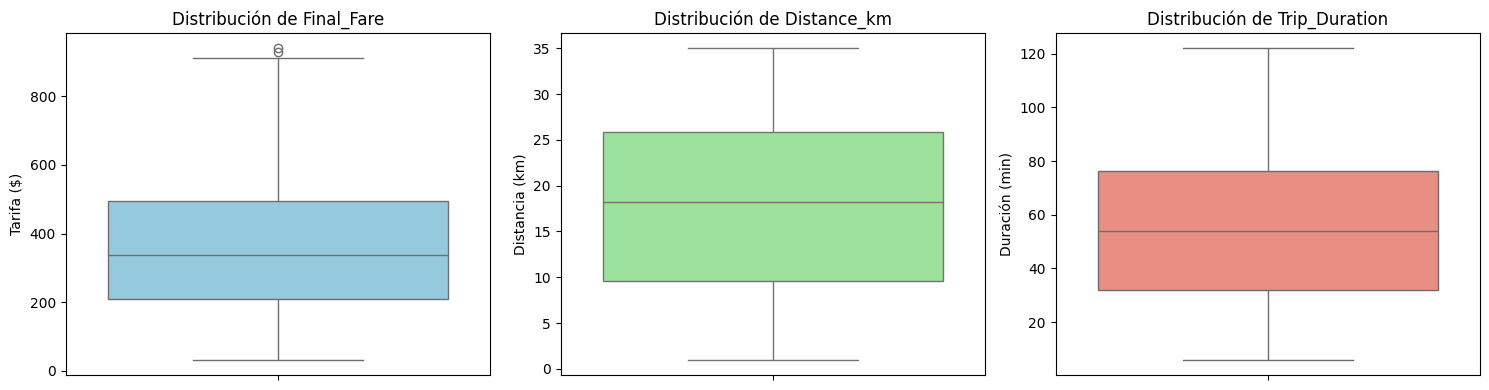

Gráficos guardados exitosamente.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.boxplot(y=df['Final_Fare'], ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Final_Fare')
axes[0].set_ylabel('Tarifa ($)')

sns.boxplot(y=df['Distance_km'], ax=axes[1], color='lightgreen')
axes[1].set_title('Distribución de Distance_km')
axes[1].set_ylabel('Distancia (km)')

sns.boxplot(y=df['Trip_Duration'], ax=axes[2], color='salmon')
axes[2].set_title('Distribución de Trip_Duration')
axes[2].set_ylabel('Duración (min)')

plt.tight_layout()
plt.savefig('distribucion.png')
plt.show()
print("Gráficos guardados exitosamente.")

In [12]:
#analisis de negocio
#correlación lineal entre Distancia y Tarifa Base
corr_dist_base = df['Distance_km'].corr(df['Base_Fare'])
print(f"Correlación Distancia vs Base_Fare: {corr_dist_base:.4f}")

Correlación Distancia vs Base_Fare: 0.9822


In [13]:
#calcular rendimiento / tarifa por kilometro
df['Fare_Per_Km'] = df['Final_Fare'] / df['Distance_km']

# Agrupación por Tipo de Vehículo
fare_by_vehicle = df.groupby('Type_of_vehicle').agg(
    Base_Fare_Prom=('Base_Fare', 'mean'),
    Final_Fare_Prom=('Final_Fare', 'mean'),
    Fare_Per_Km_Prom=('Fare_Per_Km', 'mean')
).reset_index().sort_values(by='Fare_Per_Km_Prom', ascending=False)

print(fare_by_vehicle)

  Type_of_vehicle  Base_Fare_Prom  Final_Fare_Prom  Fare_Per_Km_Prom
3             SUV      294.553498       431.331034         28.794755
4           Sedan      270.383646       384.203757         24.366686
2       Hatchback      257.668426       362.620914         23.519267
0            Auto      241.563495       348.552864         21.750061
1            Bike      226.390986       328.164413         19.480712


In [14]:
# Correlación entre desbalance de oferta/demanda y el multiplicador
corr_ratio_surge = df['Demand_Supply_Ratio'].corr(df['Surge_Multiplier'])
corr_surge_final = df['Surge_Multiplier'].corr(df['Final_Fare'])

print(f"Correlación Demand_Supply_Ratio vs Surge_Multiplier: {corr_ratio_surge:.4f}") # 0.4875
print(f"Correlación Surge_Multiplier vs Final_Fare: {corr_surge_final:.4f}") # 0.4562

Correlación Demand_Supply_Ratio vs Surge_Multiplier: 0.4875
Correlación Surge_Multiplier vs Final_Fare: 0.4562


In [15]:
# Agregación por Hora del Día
requests_por_hora = df.groupby('Hour_of_Day')['Ride_Requests'].sum().reset_index()

# Agregación por Ciudad (Nivel de desbalance de demanda)
desbalance_ciudad = df.groupby('City').agg(
    Ratio_Promedio=('Demand_Supply_Ratio', 'mean'),
    Conductores_Promedio=('No_of_active_drivers', 'mean'),
    Solicitudes_Promedio=('Ride_Requests', 'mean')
).reset_index().sort_values(by='Ratio_Promedio', ascending=False)

print(desbalance_ciudad)

        City  Ratio_Promedio  Conductores_Promedio  Solicitudes_Promedio
4     Mumbai        4.188726             49.738854            114.961783
0  Bengaluru        4.104650             50.063694            111.872611
5       Pune        3.671237             51.664948            102.989691
2      Delhi        3.253832             53.988024            112.383234
3  Hyderabad        3.251742             53.703226             99.064516
1    Chennai        2.985294             55.811765            107.829412


In [16]:
# Velocidad promedio e impacto del tráfico de Velocidad en km/h
df['Speed_kmh'] = df['Distance_km'] / (df['Trip_Duration'] / 60.0)

velocidad_trafico = df.groupby('Traffic_Level').agg(
    Velocidad_Promedio=('Speed_kmh', 'mean'),
    Duracion_Promedio=('Trip_Duration', 'mean')
).reset_index()

print(velocidad_trafico)

  Traffic_Level  Velocidad_Promedio  Duracion_Promedio
0          High           18.949613          55.872000
1           Jam           18.850911          55.155556
2           Low           19.083795          56.326693
3        Medium           18.820739          53.131004


/tmp/ipykernel_836/3660240012.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=fare_by_vehicle, x='Type_of_vehicle', y='Fare_Per_Km_Mean', ax=axes[0,0], palette='Blues_d')
/tmp/ipykernel_836/3660240012.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=city_surge, x='City', y='Avg_Ratio', ax=axes[1,1], palette='Oranges_d')


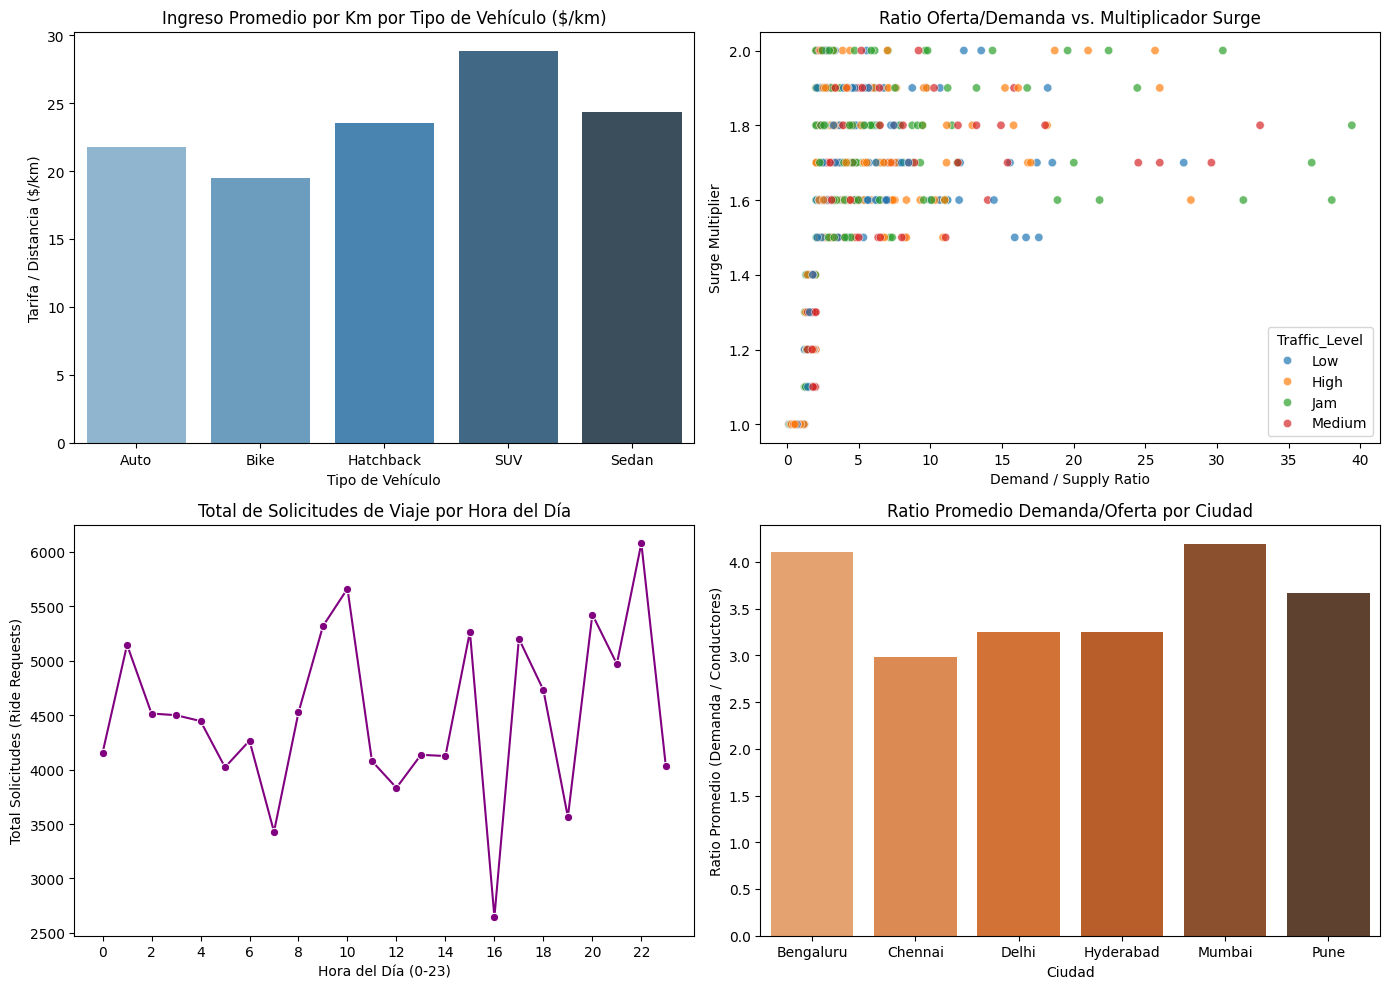

Gráficos guardados exitosamente.


In [17]:
df['Fare_Per_Km'] = df['Final_Fare'] / df['Distance_km']

# 2. Generar las agregaciones necesarias
fare_by_vehicle = df.groupby('Type_of_vehicle').agg(
    Fare_Per_Km_Mean=('Fare_Per_Km', 'mean')
).reset_index()

requests_by_hour = df.groupby('Hour_of_Day')['Ride_Requests'].sum().reset_index()

city_surge = df.groupby('City').agg(
    Avg_Ratio=('Demand_Supply_Ratio', 'mean')
).reset_index()

# 3. Crear figura y subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Grafico 1: Ingreso por Km por Tipo de Vehículo
sns.barplot(data=fare_by_vehicle, x='Type_of_vehicle', y='Fare_Per_Km_Mean', ax=axes[0,0], palette='Blues_d')
axes[0,0].set_title('Ingreso Promedio por Km por Tipo de Vehículo ($/km)')
axes[0,0].set_ylabel('Tarifa / Distancia ($/km)')
axes[0,0].set_xlabel('Tipo de Vehículo')

# Grafico 2: Oferta/Demanda vs Surge
sns.scatterplot(data=df, x='Demand_Supply_Ratio', y='Surge_Multiplier', hue='Traffic_Level', alpha=0.7, ax=axes[0,1])
axes[0,1].set_title('Ratio Oferta/Demanda vs. Multiplicador Surge')
axes[0,1].set_xlabel('Demand / Supply Ratio')
axes[0,1].set_ylabel('Surge Multiplier')

# Grafico 3: Solicitudes por Hora
sns.lineplot(data=requests_by_hour, x='Hour_of_Day', y='Ride_Requests', marker='o', ax=axes[1,0], color='purple')
axes[1,0].set_title('Total de Solicitudes de Viaje por Hora del Día')
axes[1,0].set_xlabel('Hora del Día (0-23)')
axes[1,0].set_ylabel('Total Solicitudes (Ride Requests)')
axes[1,0].set_xticks(range(0, 24, 2))

# Grafico 4: Demanda/Oferta por Ciudad
sns.barplot(data=city_surge, x='City', y='Avg_Ratio', ax=axes[1,1], palette='Oranges_d')
axes[1,1].set_title('Ratio Promedio Demanda/Oferta por Ciudad')
axes[1,1].set_ylabel('Ratio Promedio (Demanda / Conductores)')
axes[1,1].set_xlabel('Ciudad')

plt.tight_layout()
plt.savefig('punto2_punto3_charts.png')
plt.show()
print("Gráficos guardados exitosamente.")

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Cargar dataset y definir variables
df = pd.read_csv('UrbanCabFare.csv')

VARIABLE_OBJETIVO = 'Final_Fare'
VARIABLES_PREDICTORAS = ['Distance_km', 'Traffic_Level']

# 2. Separar X e y + Codificar la variable categórica Traffic_Level
X = df[VARIABLES_PREDICTORAS].copy()
X = pd.get_dummies(X, columns=['Traffic_Level'], drop_first=True)
y = df[VARIABLE_OBJETIVO]

# 3. Dividir datos (Corregido test_size)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 5. Predicción
y_pred = modelo.predict(X_test)

# 6. Evaluación
print("--- Resultados de la Regresión Lineal ---")
print(f"Intersección (Beta 0): {modelo.intercept_:.4f}")
for var, coef in zip(X.columns, modelo.coef_):
    print(f"Coeficiente para '{var}': {coef:.4f}")

print(f"\nError Cuadrático Medio (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Coeficiente de Determinación (R²): {r2_score(y_test, y_pred):.4f}")

--- Resultados de la Regresión Lineal ---
Intersección (Beta 0): 54.4488
Coeficiente para 'Distance_km': 17.7648
Coeficiente para 'Traffic_Level_Jam': 4.1257
Coeficiente para 'Traffic_Level_Low': -7.7927
Coeficiente para 'Traffic_Level_Medium': -9.5563

Error Cuadrático Medio (MSE): 11780.8868
Coeficiente de Determinación (R²): 0.6864
